In [ ]:

#bibliotecas para incializar
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import numpy as np

#calculo dixon
def dixon(s23,s46):
    
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2
         
    ff = rf / (rf + rw)
    
    return(ff)

In [ ]:
from numpy import log,exp

#calculo triplo eco
def tripleEcho(voxelSignal,tEchoes):
    
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    s4 = voxelSignal[3]
    deltaTE = tEchoes[1]-tEchoes[0]
    t2s = deltaTE*log(s2/s4)
    
    rw = (s2 * exp(tEchoes[1]/t2s) + s1* exp(tEchoes[0]/t2s))/2
    rf = (s2 * exp(tEchoes[1]/t2s) - s1* exp(tEchoes[0]/t2s))/2
         
    ff = rf / (rf + rw)
    
    return(ff)

In [ ]:
#importa arquivo csv ImageJ de ROI (#,X,Y,value)
import numpy as np
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[1:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)

In [ ]:
#normalize intensities list using Frobenius norm
import numpy as np
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized, np.linalg.norm (roi_intensities))

In [ ]:
#define pdf for Rice (probability distribution function)
import numpy as np
def func(x, v, s):
    f = (x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return f

In [ ]:
#coleta estatisticas da ROI (não utilizado)
import numpy as np
def roi_stats(roi_normalized):
    roi_mean = np.mean(roi_normalized)
    
    roi_variance = np.var(roi_normalized)
    
    roi_histogram = np.histogram(roi_normalized) #check for different bin count methods
    return (roi_mean, roi_variance, roi_histogram)

In [ ]:
#coleta estatisticas da ROI supondo distr. Rayleigh (não utilizado)
import numpy as np
def rayleigh_stats(roi_average, roi_variance):
    rayleigh_mu = 0
    
    rayleigh_sigmaMean = roi_average/np.sqrt(np.pi/2) #calculated from avg
    
    rayleigh_sigmaVar = np.sqrt(2*roi_variance/(4-np.pi)) #calculated from var
    
    return (rayleigh_mu, rayleigh_sigmaMean, rayleigh_sigmaVar)

In [ ]:
#coleta estatisticas da ROI supondo distr. Gaussiana (não utilizado)
import numpy as np
def gauss_stats(roi_average, roi_variance):
    gauss_mu = roi_average
    
    gauss_sigma = np.sqrt(roi_variance)
    
    return (gauss_mu, gauss_sigma)

In [85]:
import numpy as np
def discrete_GRE(fat_fraction, n_echoes, t2star):
    #this function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    #considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    #This is based on studies by Hamilton and Yokoo.
    #parameters: fat_fraction -> float ]0-1]
    #            n_echoes     -> integer >0, number of equally spaced echoes
    #            t2star       -> float ]0-np.inf], single t2* for everyone
    #returns:    Sabs (absolute signal intensity), echo_times
    
    #determine fat and water proton densities (rho) based on
    #a given fat fraction. rho_fat is arbitrarily defined as 0.05
    rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-fat_fraction)/fat_fraction)))
    
    rho = np.array([rho_fat*0.047,\
      rho_fat*0.039,\
      rho_fat*0.006,\
      rho_fat*0.12,\
      rho_fat*0.7,\
      rho_fat*0.088,\
      rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    '''
    #standard, individual T2* values
    t2star = [0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] '''
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star)*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return (Sabs,echo_times)

In [84]:
import numpy as np
def continuous_GRE(fat_fraction, endpoint, t2star, n_points=1000):
    #this function calculates the pseudo-continuous GRE IP-OP signal from human liver,
    #considering a low flip angle (Taylor approx. around zero) and 3T. It plots 1000 points
    #This is based on studies by Hamilton and Yokoo.
    #parameters: fat_fraction -> float ]0-1]
    #            endpoint     -> float >0, endpoint of simulation
    #            t2star       -> float ]0-np.inf]
    #            n_points (optional) -> integer > 0 number of points to be plotted
    #returns:    Sabs (absolute signal intensity), echo_times
    
    #determine fat and water proton densities (rho) based on
    #a given fat fraction. rho_fat is arbitrarily defined as 0.05
    rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-fat_fraction)/fat_fraction)))
    
    rho = np.array([rho_fat*0.047,\
      rho_fat*0.039,\
      rho_fat*0.006,\
      rho_fat*0.12,\
      rho_fat*0.7,\
      rho_fat*0.088,\
      rho_water]) #rho for each fat depends of the fat molecule (Hamilton)
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0, endpoint, n_points, endpoint=True)
    
    '''
    #standard, individual T2* values
    t2star = [0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] '''
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star)*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return (Sabs,echo_times)

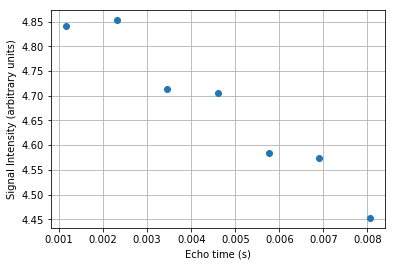

In [86]:
import matplotlib.pyplot as plt
signal_intensity, TE = discrete_GRE(0.01, 7, 0.082)

fig, ax = plt.subplots()    
ax.plot(TE,signal_intensity,'o')
plt.xlabel('Echo time (s)')
plt.ylabel('Signal Intensity (arbitrary units)')
plt.grid()
plt.show()


In [ ]:
import numpy as np

#calculo dixon
def calc_dixon(s):
    #This function calculates the fat fraction according to Dixon's method.
    #It uses only the first and second echoes of a given GRE IP-OP signal (s[0] and s[1]).
    #parameters: s -> array of signal intensities
    #returns:    ff -> float, fat fraction
    
    
    rho_w = np.array((s[1] + s[0])/2)
    rho_f = np.array((s[1] - s[0])/2)
         
    ff = rho_f / (rho_f + rho_w)
    
    return(ff)

In [ ]:
import numpy as np
def discrete_GRE_rice(fat_fraction, n_echoes, t2star):
    #this function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    #considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    #This is based on studies by Hamilton and Yokoo.
    #parameters: fat_fraction -> float ]0-1]
    #            n_echoes     -> integer >0, number of equally spaced echoes
    #            t2star       -> float ]0-np.inf], single t2* for everyone
    #returns:    Sabs (absolute signal intensity), echo_times
    
    #determine fat and water proton densities (rho) based on
    #a given fat fraction. rho_fat is arbitrarily defined as 0.05
    rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-fat_fraction)/fat_fraction)))
    
    rho = np.array([rho_fat*0.047,\
      rho_fat*0.039,\
      rho_fat*0.006,\
      rho_fat*0.12,\
      rho_fat*0.7,\
      rho_fat*0.088,\
      rho_water]) #rho for each fat depends of the fat molecule (Hamilton)
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    '''
    #standard, individual T2* values
    t2star = [0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] '''
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star)*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return (Sabs,echo_times)